# Aerotech Analog I/O Response:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from numpy.typing import NDArray
from scipy.signal import find_peaks

from datetime import datetime

In [7]:
filename = "testanalog100mms_20261104_besttest.csv"
df = pd.read_csv(filename, skipinitialspace=True)
print(df.columns)
time = df["Time (seconds)"]
pos_feedback = df["PosFbk (X) mm"]
current_command = df["CurCmd (X)"]
current_feedback = df["CurFbk (X)"]
vel_feedback = df["VelFbk (X) mm/sec"]
accel_feedback = pd.to_numeric(df["AccFbk (X)"], errors="coerce")
analog_in_ch0 = df["Ain0 (X)"]
resol = time[1] - time[0]
print(f"Time collection resolution: {resol*1000:.2f}ms")

Index(['Time (seconds)', 'PosCmd (X) mm', 'PosFbk (X) mm', 'CurFbk (X)',
       'AxisStatus (X)', 'Ain0 (X)', 'TaskState (Task 1)', 'PosErr (X) mm',
       'VelCmd (X) mm/sec', 'VelFbk (X) mm/sec', 'VelErr (X) mm/sec',
       'CurCmd (X)', 'CurErr (X)', 'DriveStatus (X)', 'ProgLineNum (Task 1)',
       'MotionLineNum (Task 1)', 'AccCmd (X)', 'AccFbk (X)', 'AccErr (X)'],
      dtype='str')
Time collection resolution: 1.00ms


In [ ]:
# accel_feedback is super noisy; why?
# answer: the first NaN value tells pandas' auto type casting to stop reading numbers
#  --> string casting being plotted is bad results
print(accel_feedback)

0                NaN
1           3.356934
2          -6.713867
3           0.610352
4           9.460449
            ...     
21220    1242.370605
21221     919.189453
21222     510.559082
21223     139.770508
21224    -130.310059
Name: AccFbk (X), Length: 21225, dtype: float64


In [3]:
def find_spikes(xdata, ydata, threshold = 1.0, min_data_gap = 20, advanced=False) -> tuple[NDArray, NDArray]:
    # finds where data spikes in slope --> graph spikes
    # focuses on mostly monotonically increasing graphs
    xdata = np.asarray(xdata)
    ydata = np.asarray(ydata)

    dy = np.diff(ydata)
    dx = np.diff(xdata)
    slope = dy / dx
    slope_change = np.diff(slope)

    if (advanced):
        spike_indices, _ = find_peaks(slope_change, height=threshold, distance=20)
        spike_indices += 1
    else:
        spike_indices = np.where(slope_change > threshold)[0] + 1
        if spike_indices.size:
            keep = np.insert(np.diff(spike_indices) > min_data_gap, 0, True)
            spike_indices = spike_indices[keep]
    # data shifts by 1 after performing np.diff, so + 1 back into index

    return spike_indices, xdata[spike_indices]


In [4]:
pos_spike_idx, pos_spike_times = find_spikes(time, pos_feedback, threshold=1.0, advanced=False)
print(len(pos_spike_idx))
print(pos_spike_idx)
print(pos_spike_times)

12
[   13   458   583   934   979  1053  2210  7275 11315 15478 19580 21214]
[1.3000e-02 4.5800e-01 5.8300e-01 9.3400e-01 9.7900e-01 1.0530e+00
 2.2100e+00 7.2750e+00 1.1315e+01 1.5478e+01 1.9580e+01 2.1214e+01]


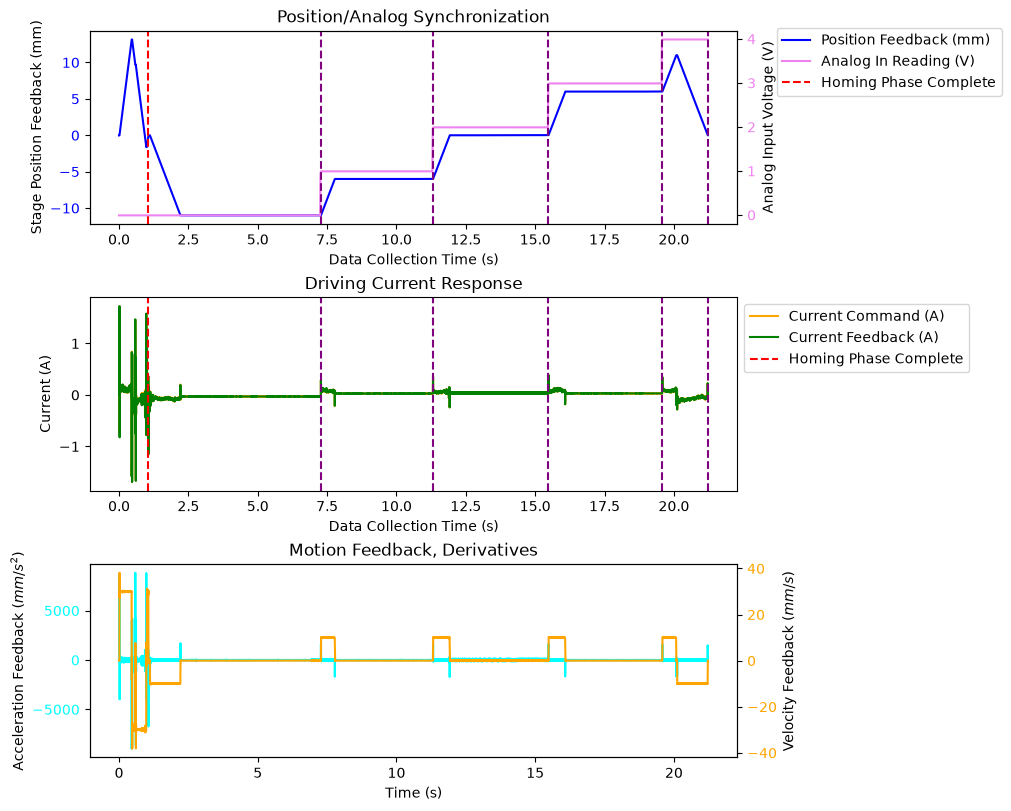

In [12]:
fig, ax = plt.subplots(3, 1, figsize=(10, 8), layout="constrained")
ax[0].plot(time, pos_feedback, color="blue", label="Position Feedback (mm)")
ax[0].xaxis.set_major_locator(MaxNLocator(nbins=10))
ax[0].set_title("Position/Analog Synchronization")
ax[0].set_xlabel("Data Collection Time (s)")
ax[0].set_ylabel("Stage Position Feedback (mm)")
ax[0].tick_params(axis='y', labelcolor="blue")
ax_analog = ax[0].twinx()
ax_analog.plot(time, analog_in_ch0, color="violet", label="Analog In Reading (V)")
homing_complete0 = ax_analog.axvline(x=pos_spike_times[5], color="red", linestyle="--", 
                                    label="Homing Phase Complete")
for pos_spike_time in pos_spike_times[7:]:
    ax_analog.axvline(x=pos_spike_time, color="purple", linestyle="--")
ax_analog.set_ylabel("Analog Input Voltage (V)")
ax_analog.tick_params(axis='y', labelcolor="violet")

ax[1].plot(time, current_command, color="orange", label="Current Command (A)")
ax[1].plot(time, current_feedback, color="green", label="Current Feedback (A)")
homing_complete1 = ax[1].axvline(x=pos_spike_times[5], color="red", linestyle="--", 
                                    label="Homing Phase Complete")
for pos_spike_time in pos_spike_times[7:]:
    ax[1].axvline(x=pos_spike_time, color="purple", linestyle="--")
ax[1].xaxis.set_major_locator(MaxNLocator(nbins=10))
ax[1].set_title("Driving Current Response")
ax[1].set_xlabel("Data Collection Time (s)")
ax[1].set_ylabel("Current (A)")

ax[2].plot(time, accel_feedback, color="cyan", label="Acceleration Feedback")
ax[2].set_title("Motion Feedback, Derivatives")
ax[2].set_xlabel("Time (s)")
ax[2].set_ylabel("Acceleration Feedback $(mm/s^2)$")
ax[2].tick_params(axis='y', labelcolor="cyan")
ax_vel = ax[2].twinx()
ax_vel.plot(time, vel_feedback, color="orange", label="Velocity Feedback")
ax_vel.set_ylabel(f"Velocity Feedback $(mm/s)$")
ax_vel.tick_params(axis='y', labelcolor="orange")


handles0, labels0 = ax[0].get_legend_handles_labels()
handles_analog, labels_analog = ax_analog.get_legend_handles_labels()
ax[0].legend(handles0 + handles_analog, labels0 + labels_analog, 
             loc="upper left", bbox_to_anchor=(1.05, 1.05))
ax[1].legend(loc="upper left", bbox_to_anchor=(1, 1))

date_str = datetime.now().strftime("%Y-%m-%d")
plt.savefig(f"./analog_io_timing_{date_str}.jpg")
plt.show()